# Mansonia whole-proteome S2F predictions

Analysis of the S2F runs on the full predicted proteomes of *Mansonia humeralis* (12,245 proteins) and
*Mansonia titillans* (13,700 proteins), compared with the earlier runs on the 283 candidate proteins per species
and with the calls in Claudio Struchiner's report (2026-08-28). The earlier comparison notebook
`checking_prediction_mansonia.ipynb` is left unchanged; this notebook re-uses its report transcription and
most-specific-term method.

S2F scores are unitless propagation scores, not probabilities. Nothing here is experimental validation; the
goal is to judge which predictions are specific enough to prioritise for follow-up.

## Observed results (executed 2026-10-14)

1. **Runs and inputs check out.** Both proteome runs completed (4.2 and 4.7 days, ~85-92 h of it in STRING graph
   collection) with exactly the proteome FASTAs; their configs differ from the candidate configs only in `alias`
   and `fasta`. Each protein received a score for ~26,200 GO terms (candidate runs: ~10,500).
2. **Raw score magnitude mostly tells you the evidence source.** Top-10 terms backed by the protein's own InterPro
   seed score ~0.15-0.37, terms backed only by its own HMMER seed sit in a narrow band at ~0.099 (the 0.1 HMMER
   weight), and terms with no own seed - reached only through the graph - have median scores of ~0.001.
   16.9% (humeralis) and 17.4% (titillans) of proteins have **no seed at all**; their best score is ~0.003 and only
   115 of them per species have any top-10 term that stands out from the proteome background.
3. **The combined graph is complete, and at proteome scale its uniform floor is half of each protein's
   connectivity.** S2F's legacy homology graph gives every non-homologous pair a floor weight, so all
   74.96 M / 93.82 M protein pairs are connected; 99.15% of edges carry only that floor. The floor accounts for a
   median 48% / 45% of a protein's weighted degree in the proteome runs versus 4% / 3% in the 283-protein runs.
   Graph-only scores are therefore pulled toward a proteome-wide average profile, which is why general terms
   (cytosol, protein binding) appear in the top-10 of over half of all proteins.
4. **The report's very low-score calls (~1e-4) are background, not weak signal.** The 13 report calls with
   candidate-run scores below 1e-3 (the cuticle/chitin and most chemosensory examples) have a median proteome
   term percentile of 0.33: most proteins in the proteome score as high or higher for the same term. Only one
   (pupal cuticle constituent, percentile 0.98) stands out. The 39 calls with scores >= 1e-3 have a median
   percentile of 0.994 (37/39 >= 0.9). The cuticle and chemosensory *categories* are not weak, though: 72/175
   (humeralis) and 70/168 (titillans) cuticle candidates score chitin binding >= 0.01, and in the proteome run every
   cuticle candidate with chitin binding in its top-10 is above the 90th percentile.
5. **Same genes, bigger network: core signatures persist, details change.** 224/283 (humeralis) and 241/283
   (titillans) candidates map to a proteome protein. Their top-10 lists share a median 6 of 10 terms with the
   candidate run and keep the same top-1 specific term in 71% / 79% of cases; chemosensory candidates are the most
   stable (median Spearman 0.86/0.87), cuticle candidates the least (0.35/0.36). Of the 60 report calls, 26 remain in the proteome top-10, 26 are present lower down, 7 belong
   to loci not recovered in the proteome and 1 GO name is unresolved (candidate run: 37 / 22 / - / 1).
6. **Proteome-wide screen finds the expected families and new proteins.** Category GO terms (with descendants)
   reach the top-10 of 148/138 chemosensory and 289/343 cuticle/chitin proteins, of which 103/83 and 160/215 were
   not among the earlier candidates. Recall of the earlier candidates by their own category is high for
   chemosensory (0.94/0.92) and cuticle (0.85/0.84) but low for mechanosensory (0.20/0.23) and zero for tracheal,
   whose candidates are predicted with generic kinase/channel functions rather than process terms.
7. **The two species agree.** For 6,048 1:1 protein pairs built from the same reference protein, the median
   Jaccard similarity of their top-10 lists is 0.67 (random cross-species pairs: 0.05).

## Scope, inputs and evidence limits

- **Runs:** `mansonia_humeralis`, `mansonia_titillans` (283 candidates each, 2026-09-21/22) and
  `mansonia_humeralis_proteome`, `mansonia_titillans_proteome` (whole proteomes, 2026-10-01/06), all with full
  STRING v12, InterPro (alpha 0.9) + HMMER (beta 0.1) seeds and no Foldseek/PLM seed. Outputs are read from
  `/run/media/marcelo_baez/HD_Disc1/.S2F/output/`; nothing there is modified.
- **Proteomes:** the miniprot homology-based gene models described in `doc/mansonia_genome_to_proteome.md`. Genes
  without a detectable mosquito homolog are absent, and 59 (humeralis) / 42 (titillans) earlier candidates have no
  near-identical counterpart in the proteome.
- **Collaborator report:** only the term-level calls printed in the PDF are available (transcribed in
  `checking_prediction_mansonia.ipynb`); the report's own reduced-network (4-species STRING) matrices are not.
  Comparisons with the report therefore use our full-STRING candidate run as the "before" state.
- **Background-aware reading:** the proteome runs give, for every GO term, the score distribution over ~12-14k
  proteins of the same organism. The term percentile measures how unusual a protein's score is for that term
  within its own proteome; it is a specificity measure, not a probability of correctness.
- **No ground truth.** There are no experimental GO annotations for *Mansonia*. Agreement between runs, species or
  reference product names measures consistency of homology-derived evidence, not accuracy.

In [1]:
from __future__ import annotations

import hashlib
import io
import json
import re
import sys
import time
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import sparse, stats

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)

WORKSPACE_ROOT = Path("/home/marcelo_baez/paccanaro-lab/PFP-Research")
S2F_ROOT = WORKSPACE_ROOT / "S2F"
S2F_HOME = Path("/run/media/marcelo_baez/HD_Disc1/.S2F")
OUTPUT_ROOT = S2F_HOME / "output"
ANNOT_DIR = S2F_ROOT / "data/mansonia/annotation"
CANDIDATE_DIR = S2F_ROOT / "data/mansonia/mansonia_candidate_proteins"
BLAST_DIR = S2F_ROOT / "notebooks/exports/mansonia_candidates_vs_proteome/blast"
EXPORT_DIR = S2F_ROOT / "notebooks/exports/mansonia_proteome_predictions"
CACHE_DIR = S2F_ROOT / "temp/mansonia_prediction_cache"   # temp/ is git-ignored
GO_OBO_PATH = S2F_ROOT / "go.obo"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

TOP_RAW_TERMS = 100        # same post-processing as the report and checking_prediction_mansonia.ipynb
TOP_SPECIFIC_TERMS = 10

SPECIES = {
    "humeralis": {
        "name": "Mansonia humeralis", "prefix": "Mhum",
        "candidate_alias": "mansonia_humeralis", "proteome_alias": "mansonia_humeralis_proteome",
        "candidate_fasta": CANDIDATE_DIR / "humeralis/humeralis_all_categories_protein.cleaned.faa",
        "extraction_summary": CANDIDATE_DIR / "humeralis/humeralis_extraction_summary.tsv",
        "proteome_fasta": ANNOT_DIR / "humeralis/humeralis_proteome.faa",
        "gene_models": ANNOT_DIR / "humeralis/humeralis_gene_models.tsv",
        "candidate_conf": S2F_ROOT / "conf/mansonia_humeralis.conf",
        "proteome_conf": S2F_ROOT / "conf/mansonia_humeralis_proteome.conf",
    },
    "titillans": {
        "name": "Mansonia titillans", "prefix": "Mtit",
        "candidate_alias": "mansonia_titillans", "proteome_alias": "mansonia_titillans_proteome",
        "candidate_fasta": CANDIDATE_DIR / "titillans/titillans_all_categories_protein.cleaned.faa",
        "extraction_summary": CANDIDATE_DIR / "titillans/titillans_extraction_summary.tsv",
        "proteome_fasta": ANNOT_DIR / "titillans/titillans_proteome.faa",
        "gene_models": ANNOT_DIR / "titillans/titillans_gene_models.tsv",
        "candidate_conf": S2F_ROOT / "conf/mansonia_titillans.conf",
        "proteome_conf": S2F_ROOT / "conf/mansonia_titillans_proteome.conf",
    },
}
RUNS = {  # (species, kind) -> S2F alias
    (sp, kind): spec[f"{kind}_alias"] for sp, spec in SPECIES.items() for kind in ("candidate", "proteome")
}
CATEGORY_LABELS = {
    "1_tracheal_spiracle": "Tracheal / spiracle",
    "2_cuticle_chitin": "Cuticle / chitin",
    "3_hypoxia_signaling": "Hypoxia signaling",
    "4_chemosensory": "Chemosensory",
    "5_mechanosensory": "Mechanosensory",
}

required = [GO_OBO_PATH, ANNOT_DIR / "refs/reference_proteins.tsv"]
for spec in SPECIES.values():
    required += [spec[k] for k in ("candidate_fasta", "extraction_summary", "proteome_fasta", "gene_models",
                                   "candidate_conf", "proteome_conf")]
for alias in RUNS.values():
    required += [OUTPUT_ROOT / alias / f for f in ("prediction.df", "run_manifest.json", "proteins.df", "terms.df")]
missing = [str(p) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError("Missing inputs (is the external disk mounted?):\n" + "\n".join(missing))

go_version = next(line.split(":", 1)[1].strip() for line in GO_OBO_PATH.open() if line.startswith("data-version:"))
print("executed     :", time.strftime("%Y-%m-%d %H:%M:%S"))
print("interpreter  :", sys.executable)
print("S2F outputs  :", OUTPUT_ROOT)
print("GO ontology  :", GO_OBO_PATH, f"({go_version})")
print("exports      :", EXPORT_DIR)

executed     : 2026-10-14 17:15:03
interpreter  : /home/marcelo_baez/anaconda3/envs/S2F/bin/python
S2F outputs  : /run/media/marcelo_baez/HD_Disc1/.S2F/output
GO ontology  : /home/marcelo_baez/paccanaro-lab/PFP-Research/S2F/go.obo (releases/2026-01-23)
exports      : /home/marcelo_baez/paccanaro-lab/PFP-Research/S2F/notebooks/exports/mansonia_proteome_predictions


## 1. Run provenance

Four S2F runs are compared: the earlier **candidate runs** (283 targeted proteins per species, the input of
the collaborator report comparison in `checking_prediction_mansonia.ipynb`) and the new **proteome runs**
(the homology-based proteomes from `doc/mansonia_genome_to_proteome.md`). The manifests are checked against
the expected FASTA and run config, and the two configs of each species are compared line by line.

In [2]:
def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def read_fasta(path: Path) -> dict[str, str]:
    seqs, name, chunks = {}, None, []
    with path.open() as handle:
        for line in handle:
            line = line.rstrip("\n")
            if line.startswith(">"):
                if name is not None:
                    seqs[name] = "".join(chunks)
                name, chunks = line[1:].split()[0], []
            else:
                chunks.append(line.strip())
    if name is not None:
        seqs[name] = "".join(chunks)
    return seqs


prov_rows, stage_rows = [], []
for (sp, kind), alias in RUNS.items():
    spec = SPECIES[sp]
    manifest = json.loads((OUTPUT_ROOT / alias / "run_manifest.json").read_text())
    expected_fasta = spec[f"{kind}_fasta"]
    expected_conf = spec[f"{kind}_conf"]
    if manifest["alias"] != alias:
        raise ValueError(f"manifest alias mismatch for {alias}")
    if Path(manifest["fasta"]).resolve() != expected_fasta.resolve():
        raise ValueError(f"{alias}: manifest FASTA {manifest['fasta']} != {expected_fasta}")
    if (S2F_ROOT / manifest["run_config"]).resolve() != expected_conf.resolve():
        raise ValueError(f"{alias}: manifest run config {manifest['run_config']} != {expected_conf}")
    events = {e["stage"]: e for e in manifest["events"]}
    if any(e["status"] != "completed" for e in manifest["events"]):
        raise ValueError(f"{alias}: not every stage completed")
    prov_rows.append({
        "species": spec["name"], "run": kind, "alias": alias,
        "started_utc": manifest["started_at"][:19],
        "finished_utc": manifest["events"][-1]["finished_at"][:19],
        "wall_days": round(sum(e["elapsed_seconds"] for e in manifest["events"]) / 86400, 2),
        "proteins_in_fasta": len(read_fasta(expected_fasta)),
        "seed_weights": manifest["seed_weights"],
        "interpreter": manifest["interpreter"],
        "fasta_md5": hashlib.md5(expected_fasta.read_bytes()).hexdigest(),
        "run_config_sha256_now": sha256(expected_conf)[:16],
        "prediction_GB": round((OUTPUT_ROOT / alias / "prediction.df").stat().st_size / 1e9, 2),
    })
    for stage, e in events.items():
        stage_rows.append({"alias": alias, "stage": stage, "hours": e["elapsed_seconds"] / 3600})

provenance = pd.DataFrame(prov_rows)
display(provenance)
display(pd.DataFrame(stage_rows).pivot(index="stage", columns="alias", values="hours").round(2)
        .loc[lambda d: d.sum(axis=1).sort_values(ascending=False).index])

# The two run configs of a species must differ only in alias, fasta and generated header comments.
for sp, spec in SPECIES.items():
    def config_lines(path):
        return {line.strip() for line in path.read_text().splitlines()
                if line.strip() and not line.startswith("#")}
    a, b = config_lines(spec["candidate_conf"]), config_lines(spec["proteome_conf"])
    diff = sorted((a ^ b))
    unexpected = [line for line in diff if not line.startswith(("alias =", "fasta ="))]
    print(f"{sp}: config lines that differ = {diff}")
    if unexpected:
        raise ValueError(f"{sp}: candidate and proteome configs differ beyond alias/fasta: {unexpected}")

,species,run,alias,started_utc,finished_utc,wall_days,proteins_in_fasta,seed_weights,interpreter,fasta_md5,run_config_sha256_now,prediction_GB
0,Mansonia humeralis,candidate,mansonia_humeralis,2026-09-21T17:07:04,2026-09-22T06:14:51,0.55,283,"{'alpha': 0.9, 'beta': 0.1, 'delta': 0, 'gamma': 0.0}",/home/marcelo_baez/anaconda3/envs/S2F/bin/python,13fdaa50f723ff0d44b7a218471c5769,b4e943a311bba4bd,0.27
1,Mansonia humeralis,proteome,mansonia_humeralis_proteome,2026-10-01T13:37:15,2026-10-05T17:28:33,4.16,12245,"{'alpha': 0.9, 'beta': 0.1, 'delta': 0, 'gamma': 0.0}",/home/marcelo_baez/anaconda3/envs/S2F/bin/python3,2f21110596abaa37ebf1ee9358762ed6,826aa08753f2db97,14.84
2,Mansonia titillans,candidate,mansonia_titillans,2026-09-22T12:02:10,2026-09-23T00:49:25,0.53,283,"{'alpha': 0.9, 'beta': 0.1, 'delta': 0, 'gamma': 0.0}",/home/marcelo_baez/anaconda3/envs/S2F/bin/python,5d60cc5ebb13dd0570d38692ae2cca77,f861353642837ae4,0.28
3,Mansonia titillans,proteome,mansonia_titillans_proteome,2026-10-06T14:33:50,2026-10-11T07:03:14,4.69,13700,"{'alpha': 0.9, 'beta': 0.1, 'delta': 0, 'gamma': 0.0}",/home/marcelo_baez/anaconda3/envs/S2F/bin/python,2dec03970fc53f32abf7b5551497241a,151fcac8704fe3fe,16.64


alias,mansonia_humeralis,mansonia_humeralis_proteome,mansonia_titillans,mansonia_titillans_proteome
stage,,,,
graph_collection,12.58,84.79,12.78,92.16
interpro_seed,0.50,9.11,0.00,13.29
hmmer_seed,0.05,3.46,0.00,3.90
homology_graph,0.00,1.87,0.00,2.44
hmmer_diffusion,0.00,0.27,0.00,0.30
prediction_output,0.00,0.20,0.00,0.22
graph_combination,0.00,0.07,0.00,0.08
interpro_diffusion,0.00,0.07,0.00,0.08
diffusion_kernel,0.00,0.01,0.00,0.01


humeralis: config lines that differ = ['alias = mansonia_humeralis', 'alias = mansonia_humeralis_proteome', 'fasta = /home/marcelo_baez/paccanaro-lab/PFP-Research/S2F/data/mansonia/annotation/humeralis/humeralis_proteome.faa', 'fasta = /home/marcelo_baez/paccanaro-lab/PFP-Research/S2F/data/mansonia/mansonia_candidate_proteins/humeralis/humeralis_all_categories_protein.cleaned.faa']
titillans: config lines that differ = ['alias = mansonia_titillans', 'alias = mansonia_titillans_proteome', 'fasta = /home/marcelo_baez/paccanaro-lab/PFP-Research/S2F/data/mansonia/annotation/titillans/titillans_proteome.faa', 'fasta = /home/marcelo_baez/paccanaro-lab/PFP-Research/S2F/data/mansonia/mansonia_candidate_proteins/titillans/titillans_all_categories_protein.cleaned.faa']


## 2. Prediction matrices

`prediction.df` is a 3-column TSV (protein, GO term, score). Each file is parsed once into a dense
protein x GO-term matrix indexed with the run's own `proteins.df` / `terms.df`, and cached under
`S2F/temp/mansonia_prediction_cache/` (git-ignored; keyed by file size and modification time, so a
re-generated prediction file invalidates the cache). Candidate-run matrices are kept in float64; proteome-run
matrices in float32 (2.4 / 2.6 GB in memory). The parser checks that no (protein, term) pair occurs twice and
that the matrix proteins are exactly the FASTA proteins.

In [3]:
def load_prediction_matrix(alias: str, dtype) -> tuple[np.ndarray, np.ndarray, np.ndarray, dict]:
    out = OUTPUT_ROOT / alias
    pred_path = out / "prediction.df"
    proteins = pd.read_pickle(out / "proteins.df")["protein idx"]
    terms = pd.read_pickle(out / "terms.df")["term idx"]
    if not (np.array_equal(np.sort(proteins.to_numpy()), np.arange(len(proteins)))
            and np.array_equal(np.sort(terms.to_numpy()), np.arange(len(terms)))):
        raise ValueError(f"{alias}: proteins.df / terms.df indices are not 0..n-1")
    protein_ids = proteins.sort_values().index.to_numpy(dtype=object)
    term_ids = terms.sort_values().index.to_numpy(dtype=object)
    st = pred_path.stat()
    cache = CACHE_DIR / f"{alias}.{st.st_size}.{int(st.st_mtime)}.{np.dtype(dtype).name}.npz"
    if cache.exists():
        with np.load(cache, allow_pickle=False) as z:
            M, info = z["M"], json.loads(str(z["info"]))
        return M, protein_ids, term_ids, info

    t0 = time.perf_counter()
    M = np.zeros((len(protein_ids), len(term_ids)), dtype=dtype)
    seen = np.zeros(M.shape, dtype=bool)
    pmap, tmap = proteins.to_dict(), terms.to_dict()
    rows = nonpositive = 0
    min_score, max_score = np.inf, -np.inf
    for chunk in pd.read_csv(pred_path, sep="\t", header=None, names=["p", "t", "s"],
                             dtype={"p": "category", "t": "category", "s": np.float64},
                             chunksize=10_000_000, na_filter=False):
        pi = chunk["p"].cat.categories.map(pmap).to_numpy()[chunk["p"].cat.codes.to_numpy()]
        ti = chunk["t"].cat.categories.map(tmap).to_numpy()[chunk["t"].cat.codes.to_numpy()]
        if pd.isna(pi).any() or pd.isna(ti).any():
            raise ValueError(f"{alias}: prediction IDs absent from proteins.df/terms.df")
        pi, ti = pi.astype(np.int64), ti.astype(np.int64)
        if seen[pi, ti].any():
            raise ValueError(f"{alias}: duplicated (protein, term) rows")
        seen[pi, ti] = True
        s = chunk["s"].to_numpy()
        M[pi, ti] = s
        rows += len(chunk)
        nonpositive += int((s <= 0).sum())
        min_score, max_score = min(min_score, s.min()), max(max_score, s.max())
    info = {"rows": rows, "nonpositive_rows": nonpositive, "min_score": float(min_score),
            "max_score": float(max_score), "proteins_with_rows": int(seen.any(axis=1).sum()),
            "parse_seconds": round(time.perf_counter() - t0, 1)}
    del seen
    np.savez(cache, M=M, info=json.dumps(info))
    return M, protein_ids, term_ids, info


PRED = {}
qc_rows = []
for (sp, kind), alias in RUNS.items():
    M, pids, tids, info = load_prediction_matrix(alias, np.float64 if kind == "candidate" else np.float32)
    fasta_ids = set(read_fasta(SPECIES[sp][f"{kind}_fasta"]))
    if set(pids) != fasta_ids:
        raise ValueError(f"{alias}: matrix proteins differ from the FASTA")
    PRED[(sp, kind)] = {"M": M, "pids": pids, "tids": tids, "pindex": {p: i for i, p in enumerate(pids)}}
    nz = M > 0
    terms_per_protein = nz.sum(axis=1)
    qc_rows.append({"species": sp, "run": kind, "alias": alias, "proteins": M.shape[0], "GO_terms_indexed": M.shape[1],
                    "rows_in_file": info["rows"], "nonpositive_rows": info["nonpositive_rows"],
                    "min_score": info["min_score"], "max_score": info["max_score"],
                    "median_terms_per_protein": int(np.median(terms_per_protein)),
                    "median_top1_score": float(np.median(M.max(axis=1)))})
    del nz

TERM_IDS = PRED[("humeralis", "proteome")]["tids"].astype(str)
for key, run in PRED.items():
    if not np.array_equal(run["tids"].astype(str), TERM_IDS):
        raise ValueError(f"term index differs for {key}")
TERM_INDEX = {t: i for i, t in enumerate(TERM_IDS)}
prediction_qc = pd.DataFrame(qc_rows)
display(prediction_qc)

,species,run,alias,proteins,GO_terms_indexed,rows_in_file,nonpositive_rows,min_score,max_score,median_terms_per_protein,median_top1_score
0,humeralis,candidate,mansonia_humeralis,283,48251,2964991,0,6.201866e-08,0.691236,10477,0.298934
1,humeralis,proteome,mansonia_humeralis_proteome,12245,48251,320525120,255,-1.073422e-06,0.756628,26176,0.227192
2,titillans,candidate,mansonia_titillans,283,48251,3003196,0,4.427928e-08,0.690915,10612,0.299276
3,titillans,proteome,mansonia_titillans_proteome,13700,48251,359461769,4430,-1.320126e-05,0.756987,26240,0.185299


### GO ontology helpers

Term names, namespaces and `is_a`/`part_of` ancestry come from S2F's `GOTool` with the workspace `go.obo`,
exactly as in `checking_prediction_mansonia.ipynb`.

In [4]:
sys.path.insert(0, str(S2F_ROOT))
from GOTool.GeneOntology import GeneOntology

ontology = GeneOntology(str(GO_OBO_PATH))
ontology.build_structure()
TERM_META = {g: (t.name, t.domain, bool(t.is_obsolete)) for g, t in ontology.terms.items()}
parent_map = {g: {p.go_id for p in t.get_parents(relations=["is_a", "part_of"])} for g, t in ontology.terms.items()}
child_map = defaultdict(set)
for child, parents in parent_map.items():
    for parent in parents:
        child_map[parent].add(child)

_ancestor_cache: dict[str, frozenset] = {}


def ancestors(go_id: str) -> frozenset:
    if go_id not in _ancestor_cache:
        seen, stack = set(), list(parent_map.get(go_id, ()))
        while stack:
            p = stack.pop()
            if p not in seen:
                seen.add(p)
                stack.extend(parent_map.get(p, ()))
        _ancestor_cache[go_id] = frozenset(seen)
    return _ancestor_cache[go_id]


def descendants(go_id: str) -> set:
    seen, stack = {go_id}, [go_id]
    while stack:
        for c in child_map.get(stack.pop(), ()):
            if c not in seen:
                seen.add(c)
                stack.append(c)
    return seen


def term_name(go_id):
    return TERM_META.get(go_id, (go_id, "unknown", False))[0]


def term_namespace(go_id):
    return TERM_META.get(go_id, (go_id, "unknown", False))[1]


active_by_name = defaultdict(list)
for g, (name, ns, obsolete) in TERM_META.items():
    if not obsolete:
        active_by_name[name.casefold()].append(g)
print(f"{len(TERM_META):,} GO terms; {sum(map(len, parent_map.values())):,} is_a/part_of edges")

48,251 GO terms; 65,919 is_a/part_of edges


## 3. What drives each protein's scores: seeds and network

S2F diffuses two seed matrices (InterPro, weight 0.9; HMMER against SwissProt, weight 0.1) over a combined
protein-protein graph. Proteins without any seed receive scores only through the graph. The combined graph is
read from `graphs/combined/<alias>.npz` (upper triangle). Its legacy homology component gives **every pair
without a BLAST hit a small floor weight** (`graphs/homology.py`: e-value 10 -> `-log(10/11)/max`), so the
graph is complete and every protein is weakly connected to every other one. The table splits each protein's
weighted degree into this uniform floor and the informative (homology hit and/or STRING-transferred) edges.

In [5]:
seed_rows = []
SEEDS = {}
for (sp, kind), alias in RUNS.items():
    ip = sparse.load_npz(S2F_HOME / "seeds/interpro" / f"{alias}.seed.npz").tocsr()
    hm = sparse.load_npz(S2F_HOME / "seeds/hmmer" / f"{alias}.seed.npz").tocsr()
    if ip.shape != PRED[(sp, kind)]["M"].shape or hm.shape != ip.shape:
        raise ValueError(f"{alias}: seed shape does not match the prediction matrix")
    SEEDS[(sp, kind)] = {"ip": ip, "hmmer": hm}
    has_ip, has_hm = np.diff(ip.indptr) > 0, np.diff(hm.indptr) > 0
    PRED[(sp, kind)]["seed_status"] = np.select(
        [has_ip & has_hm, has_ip, has_hm], ["InterPro + HMMER", "InterPro only", "HMMER only"], "no seed")
    n = len(has_ip)
    seed_rows.append({"species": sp, "run": kind, "proteins": n,
                      "InterPro + HMMER": int((has_ip & has_hm).sum()), "InterPro only": int((has_ip & ~has_hm).sum()),
                      "HMMER only": int((~has_ip & has_hm).sum()), "no seed": int((~has_ip & ~has_hm).sum()),
                      "no seed %": round(100 * (~has_ip & ~has_hm).mean(), 1)})
seed_summary = pd.DataFrame(seed_rows)
display(seed_summary)

graph_rows = []
for (sp, kind), alias in RUNS.items():
    G = sparse.load_npz(S2F_HOME / "graphs/combined" / f"{alias}.npz").tocoo()
    n = PRED[(sp, kind)]["M"].shape[0]
    if G.shape != (n, n):
        raise ValueError(f"{alias}: combined graph shape {G.shape} != {n}")
    off_diag = G.row != G.col   # the npz stores each unordered pair once (upper triangle)
    rows, cols, w = G.row[off_diag], G.col[off_diag], G.data[off_diag]
    values, counts = np.unique(w, return_counts=True)
    floor = values[np.argmax(counts)]
    is_floor = np.isclose(w, floor, rtol=1e-9, atol=0)
    deg_floor = np.bincount(rows[is_floor], w[is_floor], n) + np.bincount(cols[is_floor], w[is_floor], n)
    deg_info = np.bincount(rows[~is_floor], w[~is_floor], n) + np.bincount(cols[~is_floor], w[~is_floor], n)
    n_info = np.bincount(rows[~is_floor], minlength=n) + np.bincount(cols[~is_floor], minlength=n)
    with np.errstate(invalid="ignore", divide="ignore"):
        floor_share = deg_floor / (deg_floor + deg_info)
    PRED[(sp, kind)]["informative_degree"] = n_info
    PRED[(sp, kind)]["floor_share"] = floor_share
    graph_rows.append({
        "species": sp, "run": kind, "proteins": n, "edges": len(w),
        "complete_graph_edges": n * (n - 1) // 2,
        "floor_weight": float(floor), "floor_edges_%": round(100 * is_floor.mean(), 2),
        "informative_edges": int((~is_floor).sum()),
        "median_informative_neighbours": int(np.median(n_info)),
        "proteins_without_informative_edge": int((n_info == 0).sum()),
        "median_floor_share_of_degree": round(float(np.nanmedian(floor_share)), 3),
        "proteins_without_any_edge": int(((deg_floor + deg_info) == 0).sum()),
    })
    isolated = PRED[(sp, kind)]["pids"][(deg_floor + deg_info) == 0]
    if len(isolated):
        print(f"{alias}: proteins with no edge at all in the combined graph: {list(isolated)}")
    del G
graph_summary = pd.DataFrame(graph_rows)
display(graph_summary)

,species,run,proteins,InterPro + HMMER,InterPro only,HMMER only,no seed,no seed %
0,humeralis,candidate,283,197,7,25,54,19.1
1,humeralis,proteome,12245,8297,718,1162,2068,16.9
2,titillans,candidate,283,214,3,23,43,15.2
3,titillans,proteome,13700,9140,893,1290,2377,17.4


mansonia_titillans_proteome: proteins with no edge at all in the combined graph: ['Mtit_g013159']


,species,run,proteins,edges,complete_graph_edges,floor_weight,floor_edges_%,informative_edges,median_informative_neighbours,proteins_without_informative_edge,median_floor_share_of_degree,proteins_without_any_edge
0,humeralis,candidate,283,39903,39903,0.000833,88.25,4689,21,9,0.039,0
1,humeralis,proteome,12245,74963890,74963890,0.000067,99.15,639763,36,266,0.480,0
2,titillans,candidate,283,39903,39903,0.000710,87.07,5160,25,7,0.031,0
3,titillans,proteome,13700,93824451,93838150,0.000047,99.15,796717,39,270,0.449,1


## 4. Score landscape and the proteome-wide background

With ~12-14 thousand proteins in one run, every GO term has a distribution of scores across the proteome.
For each term this notebook uses that distribution as an empirical background: a protein's **term percentile**
is the fraction of proteins in the same proteome with a strictly lower score for that term, and the
**background median** is the term's median score across the proteome. A high raw score that is also reached by
most proteins (e.g. a root or very general term) is not specific to that protein; a low raw score can still be
specific if almost no other protein reaches it. Percentiles are only available for the proteome runs (283
preselected candidates are not a meaningful background).

('humeralis', 'proteome') column sort 6.9s
('titillans', 'proteome') column sort 8.3s


,species,seed status,proteins,median top-1 raw score,median nonzero terms
0,humeralis,InterPro + HMMER,8297,0.301164,26176
1,humeralis,InterPro only,718,0.071913,26176
2,humeralis,HMMER only,1162,0.102414,26176
3,humeralis,no seed,2068,0.005075,26176
4,titillans,InterPro + HMMER,9140,0.301197,26240
5,titillans,InterPro only,893,0.071289,26240
6,titillans,HMMER only,1290,0.101528,26240
7,titillans,no seed,2377,0.003952,26240


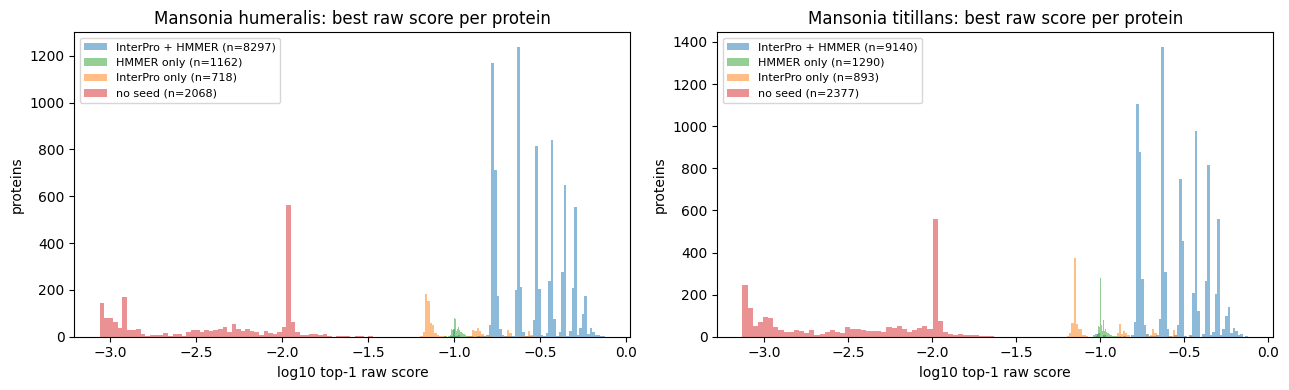

In [6]:
for key in [("humeralis", "proteome"), ("titillans", "proteome")]:
    M = PRED[key]["M"]
    t0 = time.perf_counter()
    PRED[key]["sorted_cols"] = np.sort(M, axis=0)         # per-term sorted scores across proteins
    sc = PRED[key]["sorted_cols"]
    PRED[key]["term_median"] = np.median(sc, axis=0)
    PRED[key]["term_p99"] = sc[int(np.ceil(0.99 * (sc.shape[0] - 1)))]
    print(key, f"column sort {time.perf_counter() - t0:.1f}s")


def term_percentile(key, protein_idx, term_idx):
    """Fraction of proteins in the proteome with a strictly lower score for the same term."""
    sc, M = PRED[key]["sorted_cols"], PRED[key]["M"]
    protein_idx, term_idx = np.asarray(protein_idx), np.asarray(term_idx)
    scores = M[protein_idx, term_idx]
    out = np.empty(len(scores))
    for t in np.unique(term_idx):
        sel = term_idx == t
        out[sel] = np.searchsorted(sc[:, t], scores[sel], side="left") / sc.shape[0]
    return out


land_rows = []
for key in [("humeralis", "proteome"), ("titillans", "proteome")]:
    M = PRED[key]["M"]
    status = PRED[key]["seed_status"]
    top1 = M.max(axis=1)
    for st in ["InterPro + HMMER", "InterPro only", "HMMER only", "no seed"]:
        sel = status == st
        if sel.any():
            land_rows.append({"species": key[0], "seed status": st, "proteins": int(sel.sum()),
                              "median top-1 raw score": float(np.median(top1[sel])),
                              "median nonzero terms": int(np.median((M[sel] > 0).sum(axis=1)))})
display(pd.DataFrame(land_rows))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, key in zip(axes, [("humeralis", "proteome"), ("titillans", "proteome")]):
    M, status = PRED[key]["M"], PRED[key]["seed_status"]
    for st, color in [("InterPro + HMMER", "C0"), ("HMMER only", "C2"), ("InterPro only", "C1"), ("no seed", "C3")]:
        sel = status == st
        if sel.sum() > 10:
            ax.hist(np.log10(M[sel].max(axis=1) + 1e-12), bins=60, alpha=0.5, label=f"{st} (n={sel.sum()})", color=color)
    ax.set(title=f"{SPECIES[key[0]]['name']}: best raw score per protein", xlabel="log10 top-1 raw score", ylabel="proteins")
    ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(EXPORT_DIR / "top1_score_by_seed_status.png", dpi=130)
plt.show()

## 5. Most-specific top-10 terms for every protein

Same post-processing as the report: take each protein's 100 highest-scoring terms (ties ordered by GO ID),
drop any term that is an `is_a`/`part_of` ancestor of another of those terms, keep the 10 highest remaining.
Computed for all four runs; for proteome runs each kept term also gets its term percentile, background median
and whether the protein's own InterPro or HMMER seed contains that GO term (direct seed support).

In [7]:
def top_specific(key) -> pd.DataFrame:
    run = PRED[key]
    M, pids = run["M"], run["pids"]
    records = []
    for i in range(M.shape[0]):
        row = M[i]
        positive = np.flatnonzero(row > 0)
        if len(positive) == 0:
            continue
        if len(positive) > TOP_RAW_TERMS:
            kth = np.partition(row[positive], -TOP_RAW_TERMS)[-TOP_RAW_TERMS]
            cand = positive[row[positive] >= kth]          # keep boundary ties, then order exactly
        else:
            cand = positive
        order = np.lexsort((TERM_IDS[cand], -row[cand].astype(np.float64)))
        cand = cand[order][:TOP_RAW_TERMS]
        go = TERM_IDS[cand]
        anc = set()
        for g in go:
            meta = TERM_META.get(g)
            if meta is not None and not meta[2]:
                anc |= ancestors(g)
        kept = [(t, g) for t, g in zip(cand, go) if g not in anc][:TOP_SPECIFIC_TERMS]
        for rank, (t, g) in enumerate(kept, 1):
            records.append((pids[i], i, t, g, float(row[t]), rank))
    df = pd.DataFrame(records, columns=["protein_id", "protein_idx", "term_idx", "term_id", "score", "specific_rank"])
    df["term_name"] = df["term_id"].map(term_name)
    df["namespace"] = df["term_id"].map(term_namespace)
    if key[1] == "proteome":
        df["term_percentile"] = term_percentile(key, df["protein_idx"], df["term_idx"])
        df["background_median"] = PRED[key]["term_median"][df["term_idx"]]
        ip, hm = SEEDS[key]["ip"], SEEDS[key]["hmmer"]
        df["seed_interpro"] = np.asarray(ip[df["protein_idx"].to_numpy(), df["term_idx"].to_numpy()]).ravel() > 0
        df["seed_hmmer"] = np.asarray(hm[df["protein_idx"].to_numpy(), df["term_idx"].to_numpy()]).ravel() > 0
        df["seed_status"] = PRED[key]["seed_status"][df["protein_idx"]]
    return df


TOP10 = {}
for key in PRED:
    t0 = time.perf_counter()
    TOP10[key] = top_specific(key)
    print(key, f"{len(TOP10[key]):,} rows for {TOP10[key]['protein_id'].nunique():,} proteins "
               f"in {time.perf_counter() - t0:.0f}s")

('humeralis', 'candidate') 2,830 rows for 283 proteins in 0s
('humeralis', 'proteome') 122,384 rows for 12,245 proteins in 4s
('titillans', 'candidate') 2,830 rows for 283 proteins in 0s
('titillans', 'proteome') 136,928 rows for 13,700 proteins in 5s


In [8]:
# How generic are the proteome top-10 lists? Most frequent terms and their background levels.
freq_rows = []
for key in [("humeralis", "proteome"), ("titillans", "proteome")]:
    df = TOP10[key]
    n = df["protein_id"].nunique()
    f = (df.groupby(["term_id", "term_name", "namespace"])
           .agg(proteins=("protein_id", "nunique"), median_score=("score", "median"),
                median_term_percentile=("term_percentile", "median"))
           .reset_index().sort_values("proteins", ascending=False).head(15))
    f.insert(0, "species", key[0])
    f["fraction_of_proteome"] = (f["proteins"] / n).round(3)
    freq_rows.append(f)
display(pd.concat(freq_rows, ignore_index=True))

spec_summary = []
for key in [("humeralis", "proteome"), ("titillans", "proteome")]:
    df = TOP10[key]
    spec_summary.append({
        "species": key[0], "top10 rows": len(df),
        "rows at term percentile >= 0.90": round(float((df["term_percentile"] >= 0.90).mean()), 3),
        "rows at term percentile >= 0.99": round(float((df["term_percentile"] >= 0.99).mean()), 3),
        "rows with own seed support": round(float((df["seed_interpro"] | df["seed_hmmer"]).mean()), 3),
        "proteins with >=1 term at percentile >= 0.99": int(df.loc[df["term_percentile"] >= 0.99, "protein_id"].nunique()),
    })
display(pd.DataFrame(spec_summary))

,species,term_id,term_name,namespace,proteins,median_score,median_term_percentile,fraction_of_proteome
0,humeralis,GO:0005829,cytosol,cellular_component,6725,0.097265,0.567415,0.549
1,humeralis,GO:0005515,protein binding,molecular_function,6426,0.099783,0.451123,0.525
2,humeralis,GO:0043232,intracellular membraneless organelle,cellular_component,4932,0.003261,0.356962,0.403
3,humeralis,GO:0032991,protein-containing complex,cellular_component,4176,0.006455,0.455125,0.341
4,humeralis,GO:0010467,gene expression,biological_process,3597,0.002559,0.407432,0.294
5,humeralis,GO:0005654,nucleoplasm,cellular_component,3471,0.096864,0.664108,0.283
6,humeralis,GO:0006996,organelle organization,biological_process,3246,0.000446,0.270396,0.265
7,humeralis,GO:0019538,protein metabolic process,biological_process,2748,0.003240,0.421233,0.224
8,humeralis,GO:0012505,endomembrane system,cellular_component,2604,0.001654,0.325643,0.213
9,humeralis,GO:0003676,nucleic acid binding,molecular_function,1666,0.000988,0.300367,0.136


,species,top10 rows,rows at term percentile >= 0.90,rows at term percentile >= 0.99,rows with own seed support,proteins with >=1 term at percentile >= 0.99
0,humeralis,122384,0.409,0.213,0.708,8215
1,titillans,136928,0.412,0.212,0.695,9104


### What a raw score magnitude means

The raw score of a top-10 term largely reflects **where its evidence came from**. The table groups proteome top-10
rows by the protein's own seed support for that term: InterPro seed (weight 0.9, seed values 0.08-0.77), HMMER seed
only (weight 0.1, seed value 1), or no own seed (score reaches the protein only through the graph).

In [9]:
band_rows = []
for key in [("humeralis", "proteome"), ("titillans", "proteome")]:
    df = TOP10[key].copy()
    df["support"] = np.select([df["seed_interpro"], df["seed_hmmer"]], ["own InterPro seed", "own HMMER seed only"],
                              "no own seed (graph only)")
    g = df.groupby("support")
    t = g.agg(rows=("score", "size"),
              score_p10=("score", lambda x: x.quantile(0.10)), score_median=("score", "median"),
              score_p90=("score", lambda x: x.quantile(0.90)),
              share_at_percentile_ge_0_99=("term_percentile", lambda x: (x >= 0.99).mean())).reset_index()
    t.insert(0, "species", key[0])
    band_rows.append(t)
display(pd.concat(band_rows, ignore_index=True).round(4))

noseed_rows = []
for key in [("humeralis", "proteome"), ("titillans", "proteome")]:
    df = TOP10[key]
    for st, sub in df.groupby("seed_status"):
        noseed_rows.append({"species": key[0], "protein seed status": st, "proteins": sub["protein_id"].nunique(),
                            "median top-1 specific score": sub.loc[sub["specific_rank"] == 1, "score"].median(),
                            "proteins with >=1 top-10 term at percentile >= 0.99":
                                sub.loc[sub["term_percentile"] >= 0.99, "protein_id"].nunique()})
display(pd.DataFrame(noseed_rows))

,species,support,rows,score_p10,score_median,score_p90,share_at_percentile_ge_0_99
0,humeralis,no own seed (graph only),35772,0.0003,0.0011,0.0039,0.0120
1,humeralis,own HMMER seed only,64079,0.0950,0.0991,0.0999,0.1398
2,humeralis,own InterPro seed,22533,0.1467,0.1640,0.3720,0.7383
3,titillans,no own seed (graph only),41785,0.0002,0.0007,0.0039,0.0100
4,titillans,own HMMER seed only,70375,0.0951,0.0992,0.1000,0.1428
5,titillans,own InterPro seed,24768,0.1429,0.1643,0.3671,0.7484


,species,protein seed status,proteins,median top-1 specific score,proteins with >=1 top-10 term at percentile >= 0.99
0,humeralis,HMMER only,1162,0.099210,654
1,humeralis,InterPro + HMMER,8297,0.168880,7275
2,humeralis,InterPro only,718,0.067944,171
3,humeralis,no seed,2068,0.002978,115
4,titillans,HMMER only,1290,0.099346,710
5,titillans,InterPro + HMMER,9140,0.168134,8107
6,titillans,InterPro only,893,0.068728,172
7,titillans,no seed,2377,0.002460,115


## 6. Mapping the 283 candidates onto proteome proteins

Sequence-level mapping as in `doc/mansonia_genome_to_proteome.md` (2026-09-29): identical sequence, candidate
contained in a predicted protein, predicted protein (>= 30 aa) contained in the candidate, or best BLASTP hit
with >= 95% identity over >= 90% of the candidate (`notebooks/exports/mansonia_candidates_vs_proteome/blast/`).
When several proteins qualify, the one whose gene model overlaps the candidate locus (same contig and strand)
is preferred. Only classes 1-4 are used for run-to-run comparisons.

In [10]:
LOCUS_RE = re.compile(r"(?P<contig>lcl\|ptg\d+[lc](?:_\d+)?):(?P<start>\d+)-(?P<end>\d+)\((?P<strand>[+-])\)")

mapping_frames = []
for sp, spec in SPECIES.items():
    cand = {k: v.rstrip("*") for k, v in read_fasta(spec["candidate_fasta"]).items()}
    prot = read_fasta(spec["proteome_fasta"])
    models = pd.read_csv(spec["gene_models"], sep="\t").set_index("protein_id")
    by_contig = {k: g for k, g in models.reset_index().groupby(["contig", "strand"])}
    summary = pd.read_csv(spec["extraction_summary"], sep="\t")
    summary["locus_key"] = summary["locus"].str.replace(r"^lcl\|", "", regex=True)
    blast = pd.read_csv(BLAST_DIR / f"{sp}_candidates_vs_proteome.tsv", sep="\t", header=None,
                        names=["qseqid", "sseqid", "pident", "length", "mismatch", "gapopen", "qstart", "qend",
                               "sstart", "send", "evalue", "bitscore", "qlen", "slen"])
    blast["qcov"] = (blast["qend"] - blast["qstart"] + 1) / blast["qlen"]
    best_blast = blast.sort_values("bitscore", ascending=False).drop_duplicates("qseqid").set_index("qseqid")
    by_seq = defaultdict(list)
    for pid, s in prot.items():
        by_seq[s].append(pid)
    rows = []
    for cid, s in cand.items():
        m = LOCUS_RE.search(cid)
        contig, start, end, strand = m["contig"], int(m["start"]), int(m["end"]), m["strand"]
        overlapping = []
        if (contig, strand) in by_contig:
            g = by_contig[(contig, strand)]
            overlapping = g.loc[(g["start"] <= end) & (g["end"] >= start), "protein_id"].tolist()

        def pick(ids):
            on_locus = [i for i in ids if i in overlapping]
            return (on_locus or sorted(ids, key=lambda i: -len(prot[i])))[0]

        if s in by_seq:
            cls, mapped = "1 identical", pick(by_seq[s])
        elif (hits := [p for p, ps in prot.items() if s in ps]):
            cls, mapped = "2 candidate inside longer model", pick(hits)
        elif (hits := [p for p, ps in prot.items() if len(ps) >= 30 and ps in s]):
            cls, mapped = "3 model is a fragment of candidate", pick(hits)
        elif cid in best_blast.index:
            b = best_blast.loc[cid]
            if b["pident"] >= 95 and b["qcov"] >= 0.9:
                cls, mapped = "4 near-identical (BLAST)", b["sseqid"]
            elif b["pident"] >= 95:
                cls, mapped = "5 partial (>=95% id, <90% cov)", None
            else:
                cls, mapped = "6 homolog only (<95% id)", None
        else:
            cls, mapped = "7 no BLAST hit", None
        rows.append({"species": sp, "candidate_id": cid, "locus_key": cid.split("lcl|", 1)[1],
                     "category": cid[len(sp) + 1:].split("_lcl")[0], "map_class": cls,
                     "proteome_protein": mapped, "mapped_on_locus": mapped in overlapping if mapped else False,
                     "n_models_on_locus": len(overlapping),
                     "best_blast_hit": best_blast.loc[cid, "sseqid"] if cid in best_blast.index else None,
                     "best_blast_pident": best_blast.loc[cid, "pident"] if cid in best_blast.index else np.nan,
                     "candidate_len": len(s)})
    mp = pd.DataFrame(rows).merge(summary[["locus_key", "internal_stops", "identity", "best_hit_species"]],
                                  on="locus_key", how="left", validate="one_to_one")
    mp["category_label"] = mp["category"].map(CATEGORY_LABELS)
    mapping_frames.append(mp)

candidate_mapping = pd.concat(mapping_frames, ignore_index=True)
candidate_mapping["mapped"] = candidate_mapping["proteome_protein"].notna()
display(candidate_mapping.pivot_table(index="map_class", columns="species", values="candidate_id",
                                      aggfunc="count", fill_value=0))
display(candidate_mapping.groupby(["species", "category_label"])
        .agg(candidates=("candidate_id", "size"), mapped=("mapped", "sum"),
             mapped_on_locus=("mapped_on_locus", "sum"))
        .assign(mapped_fraction=lambda d: (d["mapped"] / d["candidates"]).round(2)))
dup = candidate_mapping[candidate_mapping["mapped"]].duplicated(["species", "proteome_protein"], keep=False)
print("proteome proteins mapped by more than one candidate:", int(dup.sum()))

species,humeralis,titillans
map_class,,
1 identical,127,127
2 candidate inside longer model,69,94
3 model is a fragment of candidate,3,4
4 near-identical (BLAST),25,16
"5 partial (>=95% id, <90% cov)",5,6
6 homolog only (<95% id),32,26
7 no BLAST hit,22,10


candidates  mapped  mapped_on_locus  mapped_fraction
species   category_label                                                           
humeralis Chemosensory                 78      48               47             0.62
          Cuticle / chitin            175     155              154             0.89
          Hypoxia signaling             6       6                6             1.00
          Mechanosensory               17      10               10             0.59
          Tracheal / spiracle           7       5                5             0.71
titillans Chemosensory                 85      59               59             0.69
          Cuticle / chitin            168     155              155             0.92
          Hypoxia signaling             6       5                5             0.83
          Mechanosensory               15      13               13             0.87
          Tracheal / spiracle           9       9                9             1.00

proteome proteins mapped by more than one candidate: 10


## 7. Same genes, two runs: candidate run vs proteome run

For every candidate mapped to a proteome protein (classes 1-4), compare its predictions in the candidate run
(283-protein network) with the mapped protein's predictions in the proteome run (whole-proteome network):
overlap of the top-10 most-specific GO terms, whether the top-1 specific term is the same, and the Spearman
correlation of raw scores over the union of both runs' top-100 raw terms. Inputs differ slightly for
classes 2-4 (different sequence), which is reported separately.

In [11]:
def top100_terms(key, idx):
    row = PRED[key]["M"][idx]
    positive = np.flatnonzero(row > 0)
    if len(positive) <= TOP_RAW_TERMS:
        return positive
    kth = np.partition(row[positive], -TOP_RAW_TERMS)[-TOP_RAW_TERMS]
    return positive[row[positive] >= kth]


same_rows = []
for sp in SPECIES:
    kc, kp = (sp, "candidate"), (sp, "proteome")
    top_c = TOP10[kc].groupby("protein_id")["term_id"].apply(list).to_dict()
    top_p = TOP10[kp].groupby("protein_id")["term_id"].apply(list).to_dict()
    for r in candidate_mapping[(candidate_mapping["species"] == sp) & candidate_mapping["mapped"]].itertuples():
        ic, ip = PRED[kc]["pindex"][r.candidate_id], PRED[kp]["pindex"][r.proteome_protein]
        a, b = top_c.get(r.candidate_id, []), top_p.get(r.proteome_protein, [])
        union = np.union1d(top100_terms(kc, ic), top100_terms(kp, ip))
        rho = stats.spearmanr(PRED[kc]["M"][ic, union], PRED[kp]["M"][ip, union]).statistic if len(union) > 2 else np.nan
        same_rows.append({"species": sp, "candidate_id": r.candidate_id, "proteome_protein": r.proteome_protein,
                          "category_label": r.category_label, "map_class": r.map_class,
                          "top10_shared": len(set(a) & set(b)),
                          "top10_jaccard": len(set(a) & set(b)) / len(set(a) | set(b)) if (a or b) else np.nan,
                          "same_top1_specific": bool(a and b and a[0] == b[0]),
                          "spearman_top100_union": rho,
                          "top1_raw_candidate_run": float(PRED[kc]["M"][ic].max()),
                          "top1_raw_proteome_run": float(PRED[kp]["M"][ip].max()),
                          "proteome_seed_status": PRED[kp]["seed_status"][ip]})
same_gene = pd.DataFrame(same_rows)
display(same_gene.groupby(["species", "category_label"])
        .agg(mapped=("candidate_id", "size"), median_top10_shared=("top10_shared", "median"),
             median_jaccard=("top10_jaccard", "median"), same_top1=("same_top1_specific", "mean"),
             median_spearman=("spearman_top100_union", "median"),
             median_top1_raw_candidate=("top1_raw_candidate_run", "median"),
             median_top1_raw_proteome=("top1_raw_proteome_run", "median"))
        .round(3))
display(same_gene.groupby(["species", same_gene["map_class"].str[:1].rename("class")])
        .agg(n=("candidate_id", "size"), median_top10_shared=("top10_shared", "median"),
             same_top1=("same_top1_specific", "mean"), median_spearman=("spearman_top100_union", "median"))
        .round(3))

mapped  median_top10_shared  median_jaccard  same_top1  median_spearman  median_top1_raw_candidate  median_top1_raw_proteome
species   category_label                                                                                                                                   
humeralis Chemosensory             48                  8.0           0.667      0.771            0.858                      0.298                     0.237
          Cuticle / chitin        155                  5.0           0.333      0.697            0.354                      0.409                     0.361
          Hypoxia signaling         6                  3.5           0.213      0.667            0.451                      0.298                     0.236
          Mechanosensory           10                  3.5           0.213      0.700            0.622                      0.440                     0.377
          Tracheal / spiracle       5                  4.0           0.250      0.600            0.741                      0.203                     0.173
titillans Chemosensory             59                  7.0           0.538      0.898            0.869                      0.299                     0.237
          Cuticle / chitin        155                  6.0           0.429      0.761            0.359                      0.406                     0.311
          Hypoxia signaling         5                  4.0           0.250      0.400            0.507                      0.292                     0.235
          Mechanosensory           13                  3.0           0.176      0.923            0.418                      0.508                     0.380
          Tracheal / spiracle       9                  2.0           0.111      0.556            0.427                      0.204                     0.169

n  median_top10_shared  same_top1  median_spearman
species   class                                                      
humeralis 1      127                  5.0      0.693            0.484
          2       69                  6.0      0.754            0.649
          3        3                  6.0      0.667            0.293
          4       25                  5.0      0.680            0.462
titillans 1      127                  6.0      0.772            0.564
          2       94                  6.0      0.830            0.651
          3        4                  6.5      0.500            0.571
          4       16                  5.0      0.750            0.542

## 8. The collaborator report's calls, re-checked at proteome scale

The 60 term-level calls transcribed from the report (2026-08-28) in `checking_prediction_mansonia.ipynb` are
re-used verbatim. Each call is evaluated in the candidate run (reproducing that notebook's classification) and,
for loci mapped to the proteome, in the proteome run. For the proteome run the call's term percentile tells
whether the protein's score for that GO term stands out from the rest of the proteome.

In [12]:
REPORT_CLAIMS_TSV = """section	species	locus	term_name	report_score_text
4.1 Tracheal / spiracle	humeralis	ptg014787l_1:255566-295316(-)	protein phosphorylation	0.595
4.1 Tracheal / spiracle	humeralis	ptg014787l_1:255566-295316(-)	ATP binding	0.294
4.1 Tracheal / spiracle	humeralis	ptg014787l_1:255566-295316(-)	protein tyrosine kinase activity	0.198
4.1 Tracheal / spiracle	humeralis	ptg001450l_1:42115-44279(+)	protein dimerization activity	0.434
4.1 Tracheal / spiracle	humeralis	ptg005348l_1:195526-196667(-)	protein phosphorylation	0.142
4.1 Tracheal / spiracle	humeralis	ptg005348l_1:195526-196667(-)	ATP binding	0.116
4.1 Tracheal / spiracle	titillans	ptg003096l_1:370250-420919(-)	protein phosphorylation	0.644
4.1 Tracheal / spiracle	titillans	ptg003096l_1:370250-420919(-)	ATP binding	0.312
4.1 Tracheal / spiracle	titillans	ptg003096l_1:370250-420919(-)	protein tyrosine kinase activity	0.210
4.1 Tracheal / spiracle	titillans	ptg005525l_1:19971-56472(+)	protein phosphorylation	0.539
4.1 Tracheal / spiracle	titillans	ptg005525l_1:19971-56472(+)	ATP binding	0.214
4.1 Tracheal / spiracle	titillans	ptg008361l_1:292470-294606(-)	protein dimerization activity	0.434
4.2 Cuticle / chitin	humeralis	ptg020477l_1:129326-129676(+)	structural constituent of pupal chitin-based cuticle	approximately 1.0e-4
4.2 Cuticle / chitin	humeralis	ptg043735l_1:7643-8056(-)	chitin binding	approximately 9.9e-5
4.2 Cuticle / chitin	humeralis	ptg003655l_1:27238-33715(-)	response to chemical	approximately 9.7e-5
4.2 Cuticle / chitin	titillans	ptg027434l_1:45794-46150(+)	larval chitin-based cuticle development	approximately 9.9e-5
4.2 Cuticle / chitin	titillans	ptg006591l_1:18728-19228(-)	larval chitin-based cuticle development	approximately 9.7e-5
4.2 Cuticle / chitin	titillans	ptg014001l_1:182750-183645(+)	chitin binding	approximately 9.7e-5
4.3 Hypoxia	humeralis	ptg027774l_1:110881-151369(-)	protein dimerization activity	0.527
4.3 Hypoxia	humeralis	ptg027774l_1:110881-151369(-)	nucleus	0.205
4.3 Hypoxia	humeralis	ptg027774l_1:110881-151369(-)	transcription regulator complex	0.205
4.3 Hypoxia	humeralis	ptg027774l_1:110881-151369(-)	DNA-binding transcription factor activity	0.205
4.3 Hypoxia	humeralis	ptg010491l_1:41029-115565(-)	protein dimerization activity	0.508
4.3 Hypoxia	humeralis	ptg010491l_1:41029-115565(-)	nucleus	0.207
4.3 Hypoxia	humeralis	ptg010491l_1:41029-115565(-)	DNA-binding transcription factor activity	0.205
4.3 Hypoxia	humeralis	ptg031231l_1:34892-49056(-)	nucleus	0.209
4.3 Hypoxia	humeralis	ptg031231l_1:34892-49056(-)	transcription regulator complex	0.209
4.3 Hypoxia	humeralis	ptg031231l_1:34892-49056(-)	DNA-binding transcription factor activity	0.209
4.3 Hypoxia	humeralis	ptg011496l_1:182579-212080(+)	oxidoreductase activity, acting on paired donors, with incorporation/reduction of molecular oxygen	approximately 0.204
4.3 Hypoxia	humeralis	ptg011496l_1:182579-212080(+)	iron ion binding	0.202
4.3 Hypoxia	humeralis	ptg011496l_1:182579-212080(+)	L-ascorbic acid binding	0.107
4.3 Hypoxia	titillans	ptg010067l_1:74500-144879(+)	protein dimerization activity	0.536
4.3 Hypoxia	titillans	ptg010067l_1:74500-144879(+)	nucleus	0.209
4.3 Hypoxia	titillans	ptg010067l_1:74500-144879(+)	transcription regulator complex	0.209
4.3 Hypoxia	titillans	ptg019752l_1:154553-189619(+)	protein dimerization activity	0.521
4.3 Hypoxia	titillans	ptg019752l_1:154553-189619(+)	nucleus	0.210
4.3 Hypoxia	titillans	ptg019752l_1:154553-189619(+)	DNA-binding transcription factor activity	0.210
4.3 Hypoxia	titillans	ptg011330l_1:154587-189098(+)	nucleus	0.209
4.3 Hypoxia	titillans	ptg011330l_1:154587-189098(+)	transcription regulator complex	0.209
4.3 Hypoxia	titillans	ptg011330l_1:154587-189098(+)	DNA-binding transcription factor activity	0.209
4.4 Chemosensory	humeralis	ptg020126l_1:261877-262307(-)	odorant binding	0.324
4.4 Chemosensory	humeralis	ptg026683l_1:136-963(-)	response to carbon dioxide	approximately 9.4e-5
4.4 Chemosensory	humeralis	ptg016989l_1:21077-34066(-)	dendrite	range 7.5e-5 to 8.3e-5 across listed terms
4.4 Chemosensory	humeralis	ptg016989l_1:21077-34066(-)	signal transduction	range 7.5e-5 to 8.3e-5 across listed terms
4.4 Chemosensory	humeralis	ptg016989l_1:21077-34066(-)	neuronal cell body	range 7.5e-5 to 8.3e-5 across listed terms
4.4 Chemosensory	titillans	ptg001135l_1:131543-163831(+)	regulation of multicellular organismal process	range 9.5e-5 to 1.0e-4 across listed terms
4.4 Chemosensory	titillans	ptg001135l_1:131543-163831(+)	dendrite	range 9.5e-5 to 1.0e-4 across listed terms
4.4 Chemosensory	titillans	ptg004258l_1:171052-172633(-)	protein binding	range 5.8e-5 to 6.0e-5 across listed terms
4.4 Chemosensory	titillans	ptg004258l_1:171052-172633(-)	plasma membrane	range 5.8e-5 to 6.0e-5 across listed terms
4.4 Chemosensory	titillans	ptg018317l_1:203731-217974(+)	neuron projection	range 5.9e-5 across listed terms
4.4 Chemosensory	titillans	ptg018317l_1:203731-217974(+)	somatodendritic compartment	range 5.9e-5 across listed terms
4.5 Mechanosensory	humeralis	ptg005202l_1:143910-148202(-)	protein binding	0.528
4.5 Mechanosensory	humeralis	ptg020373l_1:22107-81775(+)	calcium channel activity	0.317
4.5 Mechanosensory	humeralis	ptg016376l_1:38948-119650(-)	calcium channel activity	0.317
4.5 Mechanosensory	humeralis	ptg003952l_1:223421-238019(-)	protein tetramerization	0.307
4.5 Mechanosensory	titillans	ptg003098l_1:149680-281827(+)	protein binding	0.427
4.5 Mechanosensory	titillans	ptg003098l_1:149680-281827(+)	calcium channel activity	0.314
4.5 Mechanosensory	titillans	ptg013409l_1:254107-328314(-)	calcium channel activity	0.322
4.5 Mechanosensory	titillans	ptg010824l_1:86502-345094(-)	protein tetramerization	0.309
4.5 Mechanosensory	titillans	ptg001371l_1:277985-281365(+)	monoatomic ion channel activity	0.209
"""
claims = pd.read_csv(io.StringIO(REPORT_CLAIMS_TSV), sep="\t", dtype=str)
claims["go_id"] = claims["term_name"].map(lambda n: (active_by_name.get(n.casefold()) or [None])[0]
                                          if len(active_by_name.get(n.casefold(), [])) == 1 else None)
claims = claims.merge(candidate_mapping[["species", "locus_key", "candidate_id", "proteome_protein", "map_class",
                                         "category_label"]],
                      left_on=["species", "locus"], right_on=["species", "locus_key"], how="left", validate="many_to_one")
if claims["candidate_id"].isna().any():
    raise ValueError("Some report loci are not among the candidates")


def evaluate(key, protein_id, go_id):
    run = PRED[key]
    if protein_id is None or pd.isna(protein_id) or go_id is None or pd.isna(go_id):
        return {}
    i, t = run["pindex"][protein_id], TERM_INDEX[go_id]
    row = run["M"][i]
    score = float(row[t])
    out = {"score": score, "raw_rank": int((row > score).sum() + 1) if score > 0 else np.nan}
    top = TOP10[key]
    hit = top[(top["protein_id"] == protein_id) & (top["term_id"] == go_id)]
    out["specific_rank"] = int(hit["specific_rank"].iloc[0]) if len(hit) else np.nan
    if key[1] == "proteome":
        out["term_percentile"] = float(term_percentile(key, [i], [t])[0])
        out["background_median"] = float(run["term_median"][t])
        out["fold_over_median"] = score / run["term_median"][t] if run["term_median"][t] > 0 else np.nan
        out["seed_status"] = run["seed_status"][i]
    return out


def classify(e):
    if not e:
        return None
    if e["score"] <= 0:
        return "absent from matrix"
    return "in top-10 specific" if not np.isnan(e["specific_rank"]) else "present, outside top-10"


rows = []
for r in claims.itertuples():
    ec = evaluate((r.species, "candidate"), r.candidate_id, r.go_id)
    ep = evaluate((r.species, "proteome"), r.proteome_protein, r.go_id)
    rows.append({
        "section": r.section, "species": r.species, "locus": r.locus, "term_name": r.term_name, "go_id": r.go_id,
        "report_score": r.report_score_text, "map_class": r.map_class,
        "cand_score": ec.get("score"), "cand_specific_rank": ec.get("specific_rank"), "cand_status": classify(ec),
        "prot_protein": r.proteome_protein, "prot_score": ep.get("score"), "prot_raw_rank": ep.get("raw_rank"),
        "prot_specific_rank": ep.get("specific_rank"),
        "prot_status": classify(ep) if ep else ("locus not recovered" if pd.notna(r.go_id) else "GO name unresolved"),
        "prot_term_percentile": ep.get("term_percentile"), "prot_background_median": ep.get("background_median"),
        "prot_fold_over_median": ep.get("fold_over_median"), "prot_seed_status": ep.get("seed_status"),
    })
report_check = pd.DataFrame(rows)
report_check.loc[report_check["go_id"].isna(), ["cand_status", "prot_status"]] = "GO name unresolved"
display(report_check)
display(pd.crosstab(report_check["cand_status"], report_check["prot_status"], margins=True))

,section,species,locus,term_name,go_id,report_score,map_class,cand_score,cand_specific_rank,cand_status,prot_protein,prot_score,prot_raw_rank,prot_specific_rank,prot_status,prot_term_percentile,prot_background_median,prot_fold_over_median,prot_seed_status
0,4.1 Tracheal / spiracle,humeralis,ptg014787l_1:255566-295316(-),protein phosphorylation,GO:0006468,0.595,1 identical,0.539620,1.0,in top-10 specific,Mhum_g007515,0.431409,13.0,1.0,in top-10 specific,0.997142,1.380255e-04,3125.574951,InterPro + HMMER
1,4.1 Tracheal / spiracle,humeralis,ptg014787l_1:255566-295316(-),ATP binding,GO:0005524,0.294,1 identical,0.272042,2.0,in top-10 specific,Mhum_g007515,0.236753,35.0,2.0,in top-10 specific,0.974520,2.668696e-04,887.147888,InterPro + HMMER
2,4.1 Tracheal / spiracle,humeralis,ptg014787l_1:255566-295316(-),protein tyrosine kinase activity,GO:0004713,0.198,1 identical,0.275110,NaN,"present, outside top-10",Mhum_g007515,0.227206,36.0,NaN,"present, outside top-10",0.999020,2.270064e-05,10008.774414,InterPro + HMMER
3,4.1 Tracheal / spiracle,humeralis,ptg001450l_1:42115-44279(+),protein dimerization activity,GO:0046983,0.434,1 identical,0.591304,1.0,in top-10 specific,Mhum_g001001,0.440235,4.0,1.0,in top-10 specific,0.999102,1.646330e-03,267.403625,InterPro + HMMER
4,4.1 Tracheal / spiracle,humeralis,ptg005348l_1:195526-196667(-),protein phosphorylation,GO:0006468,0.142,1 identical,0.137125,1.0,in top-10 specific,Mhum_g003276,0.102386,18.0,2.0,in top-10 specific,0.985953,1.380255e-04,741.793457,HMMER only
5,4.1 Tracheal / spiracle,humeralis,ptg005348l_1:195526-196667(-),ATP binding,GO:0005524,0.116,1 identical,0.114129,2.0,in top-10 specific,Mhum_g003276,0.100063,39.0,3.0,in top-10 specific,0.957207,2.668696e-04,374.949402,HMMER only
6,4.1 Tracheal / spiracle,titillans,ptg003096l_1:370250-420919(-),protein phosphorylation,GO:0006468,0.644,1 identical,0.582251,1.0,in top-10 specific,Mtit_g002603,0.434835,13.0,1.0,in top-10 specific,0.997664,9.609633e-05,4524.986328,InterPro + HMMER
7,4.1 Tracheal / spiracle,titillans,ptg003096l_1:370250-420919(-),ATP binding,GO:0005524,0.312,1 identical,0.287527,2.0,in top-10 specific,Mtit_g002603,0.238102,35.0,2.0,in top-10 specific,0.974307,1.879190e-04,1267.047729,InterPro + HMMER
8,4.1 Tracheal / spiracle,titillans,ptg003096l_1:370250-420919(-),protein tyrosine kinase activity,GO:0004713,0.210,1 identical,0.295377,NaN,"present, outside top-10",Mtit_g002603,0.229574,36.0,NaN,"present, outside top-10",0.999124,1.666914e-05,13772.422852,InterPro + HMMER
9,4.1 Tracheal / spiracle,titillans,ptg005525l_1:19971-56472(+),protein phosphorylation,GO:0006468,0.539,4 near-identical (BLAST),0.491825,1.0,in top-10 specific,Mtit_g004494,0.438508,13.0,1.0,in top-10 specific,0.998686,9.609633e-05,4563.209961,InterPro + HMMER


prot_status,GO name unresolved,in top-10 specific,locus not recovered,"present, outside top-10",All
cand_status,,,,,
GO name unresolved,1,0,0,0,1
in top-10 specific,0,21,3,13,37
"present, outside top-10",0,5,4,13,22
All,1,26,7,26,60


In [13]:
# Score-scale view: the report's "~1e-4" calls vs the proteome background for the same terms.
view = report_check.dropna(subset=["prot_score"]).copy()
view["report_band"] = np.where(view["cand_score"] < 1e-3, "report score < 1e-3", "report score >= 1e-3")
display(view.groupby(["report_band"]).agg(
    calls=("go_id", "size"),
    median_term_percentile=("prot_term_percentile", "median"),
    calls_at_percentile_ge_0_9=("prot_term_percentile", lambda s: int((s >= 0.9).sum())),
    median_fold_over_background=("prot_fold_over_median", "median")).round(3))
display(view.loc[view["report_band"] == "report score < 1e-3",
                 ["section", "species", "locus", "term_name", "report_score", "cand_score", "cand_status", "prot_protein",
                  "prot_score", "prot_status", "prot_term_percentile", "prot_background_median", "prot_seed_status"]])
display(report_check.loc[report_check["prot_status"] == "locus not recovered",
                         ["section", "species", "locus", "term_name", "map_class", "cand_score", "cand_status"]])

# Same term, all cuticle/chemosensory candidates: how often is the score far above the ~1e-4 level?
dist_rows = []
for sp in SPECIES:
    for cat, nm in [("2_cuticle_chitin", "chitin binding"), ("4_chemosensory", "odorant binding")]:
        g = TERM_INDEX[active_by_name[nm][0]]
        mp = candidate_mapping[(candidate_mapping["species"] == sp) & (candidate_mapping["category"] == cat)]
        c_scores = PRED[(sp, "candidate")]["M"][[PRED[(sp, "candidate")]["pindex"][c] for c in mp["candidate_id"]], g]
        mpm = mp[mp["mapped"]]
        p_idx = [PRED[(sp, "proteome")]["pindex"][p] for p in mpm["proteome_protein"]]
        p_scores = PRED[(sp, "proteome")]["M"][p_idx, g]
        dist_rows.append({"species": sp, "category": CATEGORY_LABELS[cat], "term": nm,
                          "candidates": len(mp), "candidate run: score >= 0.01": int((c_scores >= 0.01).sum()),
                          "candidate run: median score": float(np.median(c_scores)),
                          "proteome background median": float(PRED[(sp, "proteome")]["term_median"][g]),
                          "mapped": len(mpm), "proteome run: score >= 0.01": int((p_scores >= 0.01).sum()),
                          "proteome run: median score": float(np.median(p_scores))})
display(pd.DataFrame(dist_rows))

,calls,median_term_percentile,calls_at_percentile_ge_0_9,median_fold_over_background
report_band,,,,
report score < 1e-3,13,0.327,1,0.135
report score >= 1e-3,39,0.994,37,887.148


,section,species,locus,term_name,report_score,cand_score,cand_status,prot_protein,prot_score,prot_status,prot_term_percentile,prot_background_median,prot_seed_status
12,4.2 Cuticle / chitin,humeralis,ptg020477l_1:129326-129676(+),structural constituent of pupal chitin-based cuticle,approximately 1.0e-4,0.000015,"present, outside top-10",Mhum_g009257,0.000947,"present, outside top-10",0.984402,0.000001,HMMER only
13,4.2 Cuticle / chitin,humeralis,ptg043735l_1:7643-8056(-),chitin binding,approximately 9.9e-5,0.000097,in top-10 specific,Mhum_g012240,0.000035,"present, outside top-10",0.589873,0.000017,InterPro + HMMER
14,4.2 Cuticle / chitin,humeralis,ptg003655l_1:27238-33715(-),response to chemical,approximately 9.7e-5,0.000101,"present, outside top-10",Mhum_g002294,0.000647,"present, outside top-10",0.259943,0.004779,InterPro + HMMER
15,4.2 Cuticle / chitin,titillans,ptg027434l_1:45794-46150(+),larval chitin-based cuticle development,approximately 9.9e-5,0.000101,in top-10 specific,Mtit_g013000,0.000029,"present, outside top-10",0.589197,0.000011,InterPro + HMMER
16,4.2 Cuticle / chitin,titillans,ptg006591l_1:18728-19228(-),larval chitin-based cuticle development,approximately 9.7e-5,0.000103,in top-10 specific,Mtit_g005248,0.000022,"present, outside top-10",0.564380,0.000011,InterPro + HMMER
17,4.2 Cuticle / chitin,titillans,ptg014001l_1:182750-183645(+),chitin binding,approximately 9.7e-5,0.000100,in top-10 specific,Mtit_g009096,0.000033,"present, outside top-10",0.590219,0.000014,InterPro + HMMER
42,4.4 Chemosensory,humeralis,ptg016989l_1:21077-34066(-),dendrite,range 7.5e-5 to 8.3e-5 across listed terms,0.000094,in top-10 specific,Mhum_g008265,0.000084,"present, outside top-10",0.325766,0.000836,InterPro + HMMER
43,4.4 Chemosensory,humeralis,ptg016989l_1:21077-34066(-),signal transduction,range 7.5e-5 to 8.3e-5 across listed terms,0.000081,"present, outside top-10",Mhum_g008265,0.000148,"present, outside top-10",0.027930,0.002341,InterPro + HMMER
44,4.4 Chemosensory,humeralis,ptg016989l_1:21077-34066(-),neuronal cell body,range 7.5e-5 to 8.3e-5 across listed terms,0.000085,in top-10 specific,Mhum_g008265,0.000086,"present, outside top-10",0.292201,0.001155,InterPro + HMMER
45,4.4 Chemosensory,titillans,ptg001135l_1:131543-163831(+),regulation of multicellular organismal process,range 9.5e-5 to 1.0e-4 across listed terms,0.000102,"present, outside top-10",Mtit_g000949,0.000110,"present, outside top-10",0.086788,0.002142,InterPro + HMMER


,section,species,locus,term_name,map_class,cand_score,cand_status
34,4.3 Hypoxia,titillans,ptg019752l_1:154553-189619(+),protein dimerization activity,6 homolog only (<95% id),0.570190,in top-10 specific
35,4.3 Hypoxia,titillans,ptg019752l_1:154553-189619(+),nucleus,6 homolog only (<95% id),0.197156,in top-10 specific
36,4.3 Hypoxia,titillans,ptg019752l_1:154553-189619(+),DNA-binding transcription factor activity,6 homolog only (<95% id),0.199475,"present, outside top-10"
41,4.4 Chemosensory,humeralis,ptg026683l_1:136-963(-),response to carbon dioxide,6 homolog only (<95% id),0.000072,"present, outside top-10"
49,4.4 Chemosensory,titillans,ptg018317l_1:203731-217974(+),neuron projection,"5 partial (>=95% id, <90% cov)",0.000075,"present, outside top-10"
50,4.4 Chemosensory,titillans,ptg018317l_1:203731-217974(+),somatodendritic compartment,"5 partial (>=95% id, <90% cov)",0.000074,"present, outside top-10"
54,4.5 Mechanosensory,humeralis,ptg003952l_1:223421-238019(-),protein tetramerization,6 homolog only (<95% id),0.283012,in top-10 specific


,species,category,term,candidates,candidate run: score >= 0.01,candidate run: median score,proteome background median,mapped,proteome run: score >= 0.01,proteome run: median score
0,humeralis,Cuticle / chitin,chitin binding,175,72,0.001484,0.000017,155,62,0.000480
1,humeralis,Chemosensory,odorant binding,78,31,0.001444,0.000008,48,24,0.071764
2,titillans,Cuticle / chitin,chitin binding,168,70,0.002926,0.000014,155,63,0.002156
3,titillans,Chemosensory,odorant binding,85,34,0.001651,0.000006,59,29,0.001791


## 9. Category signatures: candidate run vs proteome run

For the category-defining GO terms used in the report and the earlier notebook (chitin binding, odorant
binding, calcium channel activity, response to hypoxia, protein phosphorylation), count how many mapped
candidates carry the term in their top-10 most-specific list in each run, and how many of the proteome-run
occurrences are above the proteome's 90th percentile for that term.

In [14]:
SIGNATURE_TERMS = {
    "2_cuticle_chitin": ["chitin binding"],
    "4_chemosensory": ["odorant binding"],
    "5_mechanosensory": ["calcium channel activity"],
    "3_hypoxia_signaling": ["response to hypoxia"],
    "1_tracheal_spiracle": ["protein phosphorylation"],
}
sig_rows = []
for sp in SPECIES:
    mapped = candidate_mapping[(candidate_mapping["species"] == sp) & candidate_mapping["mapped"]]
    for cat, names in SIGNATURE_TERMS.items():
        sub = mapped[mapped["category"] == cat]
        for nm in names:
            g = active_by_name[nm.casefold()][0]
            tc, tp = TOP10[(sp, "candidate")], TOP10[(sp, "proteome")]
            in_c = tc[(tc["term_id"] == g) & tc["protein_id"].isin(sub["candidate_id"])]
            in_p = tp[(tp["term_id"] == g) & tp["protein_id"].isin(sub["proteome_protein"])]
            sig_rows.append({"species": sp, "category": CATEGORY_LABELS[cat], "term": nm, "mapped_candidates": len(sub),
                             "in_top10_candidate_run": in_c["protein_id"].nunique(),
                             "in_top10_proteome_run": in_p["protein_id"].nunique(),
                             "proteome_hits_at_percentile_ge_0_9": int(in_p.loc[in_p["term_percentile"] >= 0.9,
                                                                                "protein_id"].nunique()),
                             "proteome_hits_with_own_seed": int(in_p.loc[in_p["seed_interpro"] | in_p["seed_hmmer"],
                                                                        "protein_id"].nunique())})
display(pd.DataFrame(sig_rows))

,species,category,term,mapped_candidates,in_top10_candidate_run,in_top10_proteome_run,proteome_hits_at_percentile_ge_0_9,proteome_hits_with_own_seed
0,humeralis,Cuticle / chitin,chitin binding,155,112,75,75,59
1,humeralis,Chemosensory,odorant binding,48,26,26,26,23
2,humeralis,Mechanosensory,calcium channel activity,10,7,3,3,3
3,humeralis,Hypoxia signaling,response to hypoxia,6,5,3,2,3
4,humeralis,Tracheal / spiracle,protein phosphorylation,5,2,2,2,2
5,titillans,Cuticle / chitin,chitin binding,155,122,91,91,61
6,titillans,Chemosensory,odorant binding,59,29,30,30,29
7,titillans,Mechanosensory,calcium channel activity,13,10,5,5,5
8,titillans,Hypoxia signaling,response to hypoxia,5,3,3,1,3
9,titillans,Tracheal / spiracle,protein phosphorylation,9,5,2,2,2


## 10. Proteome-wide screen for candidates in the five categories

The proteome runs allow looking beyond the 283 preselected loci. Each category is defined by a small set of GO
terms **plus all their descendants** (listed in the next cell). A protein is a category hit when any of these terms
is among its top-10 most-specific predictions. Each hit is annotated with its term percentile, whether the
protein's own seed contains the term, whether it is one of the mapped earlier candidates, and the product name of
its best mosquito reference protein (from the gene models). The product-name keyword match is a heuristic
consistency check, and it is **not independent**: both the product name and S2F's seeds derive from sequence
homology.

In [15]:
CATEGORY_ROOTS = {
    "1_tracheal_spiracle": ["open tracheal system development"],
    "2_cuticle_chitin": ["chitin binding", "structural constituent of chitin-based cuticle",
                         "chitin-based cuticle development", "chitin metabolic process", "chitin synthase activity"],
    "3_hypoxia_signaling": ["response to decreased oxygen levels"],
    "4_chemosensory": ["odorant binding", "olfactory receptor activity", "taste receptor activity",
                       "sensory perception of smell", "sensory perception of taste", "olfactory behavior",
                       "response to carbon dioxide"],
    "5_mechanosensory": ["detection of mechanical stimulus", "mechanosensory behavior",
                         "mechanosensitive monoatomic ion channel activity", "sensory perception of mechanical stimulus"],
}
PRODUCT_KEYWORDS = {
    "1_tracheal_spiracle": r"breathless|fibroblast growth factor|trachealess|branchless|tracheal|spiracle|"
                           r"abdominal-B|dysfusion|ventral veins lacking",
    "2_cuticle_chitin": r"cuticl|chitin|obstructor|knickkopf|serpentine|vermiform|tweedle|\bCPR|\bCPLC|\bCPF",
    "3_hypoxia_signaling": r"hypoxia|\btango|aryl hydrocarbon receptor nuclear|prolyl 4-hydroxylase|egl nine|"
                           r"\bHIF|fatiga|von Hippel",
    "4_chemosensory": r"odorant|olfactory|gustatory|chemosensory|pheromone|ionotropic receptor|sensory neuron membrane",
    "5_mechanosensory": r"piezo|nompC|no mechanoreceptor potential|transient receptor potential|\bTRP|nanchung|"
                        r"painless|pickpocket|mechanosensory|degenerin|\btmc\b|transmembrane channel",
}
category_terms = {}
for cat, names in CATEGORY_ROOTS.items():
    ids = set()
    for nm in names:
        hits = active_by_name.get(nm.casefold(), [])
        if len(hits) != 1:
            raise ValueError(f"GO name not uniquely resolved: {nm}")
        ids |= descendants(hits[0])
    category_terms[cat] = ids
    print(f"{CATEGORY_LABELS[cat]:20s} {len(names)} root term(s) -> {len(ids)} GO terms incl. descendants")

refs = pd.read_csv(ANNOT_DIR / "refs/reference_proteins.tsv", sep="\t")[["ref_id", "product"]]
screen_frames = []
for sp, spec in SPECIES.items():
    key = (sp, "proteome")
    top = TOP10[key]
    models = (pd.read_csv(spec["gene_models"], sep="\t")
              [["protein_id", "contig", "start", "end", "strand", "protein_len", "ref_id", "ref_species", "identity",
                "ref_coverage"]]
              .merge(refs, on="ref_id", how="left"))
    mapped = candidate_mapping[(candidate_mapping["species"] == sp) & candidate_mapping["mapped"]]
    mapped_cat = mapped.groupby("proteome_protein")["category"].agg(lambda s: ",".join(sorted(set(s))))
    for cat, ids in category_terms.items():
        hits = top[top["term_id"].isin(list(ids))].sort_values(["protein_id", "specific_rank"])
        best = hits.drop_duplicates("protein_id").copy()
        best["category"] = cat
        best["category_terms_in_top10"] = best["protein_id"].map(hits.groupby("protein_id")["term_name"]
                                                                 .agg(lambda s: "; ".join(s)))
        best["species"] = sp
        screen_frames.append(best.merge(models, on="protein_id", how="left")
                             .assign(earlier_candidate_category=lambda d: d["protein_id"].map(mapped_cat)))
screen = pd.concat(screen_frames, ignore_index=True)
screen["is_earlier_candidate"] = screen["earlier_candidate_category"].notna()
screen["same_category_as_earlier"] = [isinstance(e, str) and c in e.split(",")
                                      for e, c in zip(screen["earlier_candidate_category"], screen["category"])]
screen["own_seed_support"] = screen["seed_interpro"] | screen["seed_hmmer"]
screen["product_keyword_match"] = [bool(re.search(PRODUCT_KEYWORDS[c], str(p), flags=re.I))
                                   for c, p in zip(screen["category"], screen["product"])]
screen["category_label"] = screen["category"].map(CATEGORY_LABELS)

screen_summary = (screen.groupby(["species", "category_label"])
                  .agg(proteins_hit=("protein_id", "nunique"),
                       at_percentile_ge_0_99=("term_percentile", lambda s: int((s >= 0.99).sum())),
                       with_own_seed=("own_seed_support", "sum"),
                       earlier_candidates_same_category=("same_category_as_earlier", "sum"),
                       new_proteins=("is_earlier_candidate", lambda s: int((~s).sum())),
                       product_keyword_match=("product_keyword_match", "sum")))
mapped_per_cat = (candidate_mapping[candidate_mapping["mapped"]]
                  .groupby(["species", "category_label"])["proteome_protein"].nunique().rename("earlier_candidates_mapped"))
screen_summary = screen_summary.join(mapped_per_cat)
display(screen_summary)

Tracheal / spiracle  1 root term(s) -> 23 GO terms incl. descendants
Cuticle / chitin     5 root term(s) -> 14 GO terms incl. descendants
Hypoxia signaling    1 root term(s) -> 17 GO terms incl. descendants
Chemosensory         7 root term(s) -> 34 GO terms incl. descendants
Mechanosensory       4 root term(s) -> 26 GO terms incl. descendants


proteins_hit  at_percentile_ge_0_99  with_own_seed  earlier_candidates_same_category  new_proteins  product_keyword_match  earlier_candidates_mapped
species   category_label                                                                                                                                                           
humeralis Chemosensory                  148                    127            138                                44           103                     73                         47
          Cuticle / chitin              289                    236            249                               129           160                    153                        153
          Hypoxia signaling              41                      9             37                                 3            37                      2                          6
          Mechanosensory                 34                     15             34                                 2            28                      6                         10
          Tracheal / spiracle            53                     37             51                                 0            53                      1                          5
titillans Chemosensory                  138                    125            130                                54            83                     78                         59
          Cuticle / chitin              343                    283            301                               128           215                    155                        153
          Hypoxia signaling              56                      5             41                                 3            52                      1                          5
          Mechanosensory                 55                     27             53                                 3            43                      7                         13
          Tracheal / spiracle            59                     41             55                                 0            59                      0                          9

In [16]:
# Recall of the earlier candidate sets: how many mapped candidates are hits of their own category?
recall = (candidate_mapping[candidate_mapping["mapped"]]
          .merge(screen[["species", "protein_id", "category"]].rename(columns={"protein_id": "proteome_protein"})
                 .assign(hit=True),
                 on=["species", "proteome_protein", "category"], how="left"))
recall["hit"] = recall["hit"].fillna(False).astype(bool)
display(recall.groupby(["species", "category_label"]).agg(mapped=("candidate_id", "size"), own_category_hit=("hit", "sum"))
        .assign(fraction=lambda d: (d["own_category_hit"] / d["mapped"]).round(2)))

# Strongest new (not previously candidate) hits per category, ranked by term percentile then raw score.
show_cols = ["species", "category_label", "protein_id", "term_name", "specific_rank", "score", "term_percentile",
             "own_seed_support", "seed_status", "product", "ref_species", "identity", "contig", "start", "end"]
new_hits = (screen[~screen["is_earlier_candidate"]]
            .sort_values(["species", "category", "term_percentile", "score"], ascending=[True, True, False, False]))
display(new_hits.groupby(["species", "category"]).head(8)[show_cols])

mapped  own_category_hit  fraction
species   category_label                                         
humeralis Chemosensory             48                45      0.94
          Cuticle / chitin        155               131      0.85
          Hypoxia signaling         6                 3      0.50
          Mechanosensory           10                 2      0.20
          Tracheal / spiracle       5                 0      0.00
titillans Chemosensory             59                54      0.92
          Cuticle / chitin        155               130      0.84
          Hypoxia signaling         5                 3      0.60
          Mechanosensory           13                 3      0.23
          Tracheal / spiracle       9                 0      0.00

,species,category_label,protein_id,term_name,specific_rank,score,term_percentile,own_seed_support,seed_status,product,ref_species,identity,contig,start,end
0,humeralis,Tracheal / spiracle,Mhum_g000683,"liquid clearance, open tracheal system",7,0.099196,0.999837,True,InterPro + HMMER,sodium channel protein Nach,Culex_quinquefasciatus,0.7213,lcl|ptg001015l_1,3445,5657
51,humeralis,Tracheal / spiracle,Mhum_g012058,"liquid clearance, open tracheal system",7,0.099196,0.999837,True,InterPro + HMMER,sodium channel protein Nach,Culex_quinquefasciatus,0.7213,lcl|ptg039377l_1,13296,15525
12,humeralis,Tracheal / spiracle,Mhum_g003646,open tracheal system development,6,0.099250,0.999755,True,InterPro + HMMER,cap-specific mRNA (nucleoside-2'-O-)-methyltransferase 1,Aedes_aegypti,0.5229,lcl|ptg005997l_1,43598,45602
34,humeralis,Tracheal / spiracle,Mhum_g009245,"liquid clearance, open tracheal system",7,0.099195,0.999755,True,InterPro + HMMER,sodium channel protein Nach-like,Aedes_aegypti,0.6638,lcl|ptg020433l_1,189961,205517
49,humeralis,Tracheal / spiracle,Mhum_g011833,"liquid clearance, open tracheal system",7,0.099195,0.999673,True,InterPro + HMMER,sodium channel protein Nach-like,Anopheles_gambiae,0.5304,lcl|ptg036392l_1,25470,25867
23,humeralis,Tracheal / spiracle,Mhum_g006235,"liquid clearance, open tracheal system",9,0.099193,0.999592,True,InterPro + HMMER,sodium channel protein Nach,Culex_quinquefasciatus,0.5561,lcl|ptg011280l_1,436,2011
30,humeralis,Tracheal / spiracle,Mhum_g008016,"liquid clearance, open tracheal system",7,0.099192,0.999510,True,InterPro + HMMER,sodium channel protein Nach,Aedes_aegypti,0.6397,lcl|ptg016230l_1,6298,128778
37,humeralis,Tracheal / spiracle,Mhum_g009562,"spiracle morphogenesis, open tracheal system",10,0.098996,0.999510,True,HMMER only,homeotic protein empty spiracles,Culex_quinquefasciatus,0.7260,lcl|ptg021616l_1,184688,185536
311,humeralis,Cuticle / chitin,Mhum_g011178,structural constituent of pupal chitin-based cuticle,2,0.099124,0.999918,True,InterPro + HMMER,larval cuticle protein A2B,Culex_quinquefasciatus,0.6880,lcl|ptg029953l_1,41780,42151
296,humeralis,Cuticle / chitin,Mhum_g010820,structural constituent of pupal chitin-based cuticle,2,0.099122,0.999755,True,InterPro + HMMER,larval cuticle protein A2B,Culex_quinquefasciatus,0.6960,lcl|ptg027866l_1,45944,46315


## 11. Agreement between the two species

Proteins of the two species that were built from the **same reference protein**, with that reference used
exactly once in each proteome, form 1:1 putative ortholog pairs. Their top-10 most-specific lists are compared
with random cross-species pairs as a baseline.

In [17]:
gm = {sp: pd.read_csv(spec["gene_models"], sep="\t")[["protein_id", "ref_id"]] for sp, spec in SPECIES.items()}
single = {sp: g[~g["ref_id"].duplicated(keep=False)] for sp, g in gm.items()}
pairs = single["humeralis"].merge(single["titillans"], on="ref_id", suffixes=("_hum", "_tit"))
sets = {sp: TOP10[(sp, "proteome")].groupby("protein_id")["term_id"].apply(frozenset).to_dict() for sp in SPECIES}


def jaccard(a, b):
    return len(a & b) / len(a | b) if (a or b) else np.nan


pairs["top10_jaccard"] = [jaccard(sets["humeralis"].get(a, frozenset()), sets["titillans"].get(b, frozenset()))
                          for a, b in zip(pairs["protein_id_hum"], pairs["protein_id_tit"])]
rng = np.random.default_rng(20261014)
shuffled = rng.permutation(pairs["protein_id_tit"].to_numpy())
random_j = np.array([jaccard(sets["humeralis"].get(a, frozenset()), sets["titillans"].get(b, frozenset()))
                     for a, b in zip(pairs["protein_id_hum"], shuffled)])
display(pd.DataFrame([
    {"pairs": "1:1 same-reference pairs", "n": len(pairs), "median_jaccard": pairs["top10_jaccard"].median(),
     "mean_jaccard": pairs["top10_jaccard"].mean(), "identical_top10": int((pairs["top10_jaccard"] == 1).sum())},
    {"pairs": "random cross-species pairs", "n": len(random_j), "median_jaccard": np.median(random_j),
     "mean_jaccard": random_j.mean(), "identical_top10": int((random_j == 1).sum())},
]).round(3))

,pairs,n,median_jaccard,mean_jaccard,identical_top10
0,1:1 same-reference pairs,6048,0.667,0.631,912
1,random cross-species pairs,6048,0.053,0.066,0


## 12. Exported tables

Written to `S2F/notebooks/exports/mansonia_proteome_predictions/` (TSV):

| file | content |
|---|---|
| `<species>_proteome_top10_specific.tsv` | top-10 most-specific GO terms for every proteome protein, with score, term percentile, background median, seed support, gene model and reference product |
| `candidate_to_proteome_mapping.tsv` | the 283 candidates per species, mapping class and mapped proteome protein |
| `candidate_vs_proteome_same_gene.tsv` | per mapped candidate: top-10 overlap, same top-1, Spearman, top-1 raw scores |
| `report_calls_rechecked.tsv` | the 60 report calls in the candidate and proteome runs |
| `category_screen_hits.tsv` | every category hit from section 10 |
| `top1_score_by_seed_status.png` | figure from section 4 |

In [18]:
for sp, spec in SPECIES.items():
    models = pd.read_csv(spec["gene_models"], sep="\t")[["protein_id", "contig", "start", "end", "strand", "protein_len",
                                                         "ref_id", "ref_species", "identity", "ref_coverage"]]
    out = (TOP10[(sp, "proteome")].drop(columns=["protein_idx", "term_idx"])
           .merge(models.merge(refs, on="ref_id", how="left"), on="protein_id", how="left"))
    out.to_csv(EXPORT_DIR / f"{sp}_proteome_top10_specific.tsv", sep="\t", index=False, float_format="%.6g")
candidate_mapping.to_csv(EXPORT_DIR / "candidate_to_proteome_mapping.tsv", sep="\t", index=False)
same_gene.to_csv(EXPORT_DIR / "candidate_vs_proteome_same_gene.tsv", sep="\t", index=False, float_format="%.6g")
report_check.to_csv(EXPORT_DIR / "report_calls_rechecked.tsv", sep="\t", index=False, float_format="%.6g")
screen.drop(columns=["protein_idx", "term_idx"]).to_csv(EXPORT_DIR / "category_screen_hits.tsv", sep="\t", index=False,
                                                         float_format="%.6g")
for f in sorted(EXPORT_DIR.iterdir()):
    print(f"{f.name:45s} {f.stat().st_size / 1e6:8.2f} MB")

candidate_to_proteome_mapping.tsv                 0.13 MB
candidate_vs_proteome_same_gene.tsv               0.08 MB
category_screen_hits.tsv                          0.49 MB
humeralis_proteome_top10_specific.tsv            31.72 MB
report_calls_rechecked.tsv                        0.01 MB
titillans_proteome_top10_specific.tsv            35.62 MB
top1_score_by_seed_status.png                     0.06 MB


## 13. Interpretation

**What the proteome runs add.** Running S2F on the whole proteome gives every candidate a proteome-wide context
and every GO term an empirical background. That background is the most useful new tool here: it separates
predictions that are specific to a protein from scores every protein receives through propagation.

**How to read scores.** In these runs the raw score is largely a fingerprint of where the evidence came from (own
InterPro seed ~0.15-0.4, own HMMER seed ~0.1, graph only ~1e-3 or less). Ranking within a protein (as the report
recommends) is still right, but a high rank alone is not enough: the general terms that fill many top-10 lists
(cytosol, protein binding, nucleoplasm) sit near the middle of their proteome distribution. Combining the
most-specific top-10 with the term percentile and the seed-support flags (all exported) gives a better basis for
choosing which predictions to test.

**Consequences for the collaborator report.** The report's interpretation of the ~1e-4 cuticle/chitin and
chemosensory calls as "correct direction, diluted magnitude" is not supported at proteome scale: those scores lie
near or below the proteome median for their terms, i.e. at background level. The strong calls (tyrosine-kinase
signalling for tracheal candidates, bHLH-PAS/transcription-factor and Fe/2OG oxygenase profiles for hypoxia,
odorant binding, calcium-channel activity) are well above background and mostly persist: every strong call on a
recovered locus stays above the 0.88 term percentile. The calcium-channel calls illustrate why the percentile
matters: they rank outside the top-10 most-specific list in both runs, yet at proteome scale they sit above the
0.9995 percentile, i.e. they are among the most protein-specific predictions in these lists. The cuticle and
chemosensory categories do contain many strong, domain-backed predictions (chitin binding, odorant binding) that
the report's examples did not show; the report's examples came from its reduced-network run, which cannot be
re-examined here.

**Method-level observation for S2F.** The legacy homology graph connects every protein pair with a floor weight.
With 283 proteins that floor was ~4% of a protein's connectivity; with a whole proteome it is about half. This
does not create false strong predictions (seeded scores dominate), but it flattens graph-only predictions toward
a proteome-average profile and makes the ~17% unseeded proteins nearly uninformative. This is relevant to the
graph-propagation extensions planned for S2F (e.g. sparsifying or thresholding the homology graph) and should be
evaluated on a benchmark organism before changing the Mansonia runs.

**New candidates.** The screen exports (`category_screen_hits.tsv`) list every protein whose top-10 contains a
category term. The most credible new candidates combine (i) an own InterPro seed for the term, (ii) a term
percentile >= 0.99, and (iii) a reference product name consistent with the category. Hits that rely on the HMMER
band (~0.099) - e.g. many "liquid clearance, open tracheal system" and "response to hypoxia" calls - reflect GO
terms transferred from SwissProt matches (largely *Drosophila*) and are weaker hypotheses. Tracheal and
mechanosensory biology is poorly captured by process-level GO terms here; their earlier candidates are recognised
by molecular-function profiles instead.

**Limits.** Consistency across runs and species is expected in part because both species' proteins were built
from the same reference proteins and receive similar seeds; it supports stability, not correctness. All
predictions remain computational hypotheses to prioritise experiments, not substitutes for them.

## Reproduction

Run all cells with the `s2f` Jupyter kernel (`/home/marcelo_baez/anaconda3/envs/S2F/bin/python`, Python 3.13,
pandas 3.0) and the external disk mounted at `/run/media/marcelo_baez/HD_Disc1`:

```bash
cd S2F/notebooks
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=s2f \
    --ExecutePreprocessor.timeout=7200 mansonia_proteome_predictions.ipynb
```

The first execution parses the four `prediction.df` files (~680 M rows, ~6.5 min, ~15 GB RAM) and caches dense
matrices in `S2F/temp/mansonia_prediction_cache/` (git-ignored; delete to force re-parsing). Later executions take
about 1-2 minutes. Inputs: run manifests, `proteins.df`/`terms.df`, seed matrices (`seeds/{interpro,hmmer}/`),
combined graphs (`graphs/combined/*.npz`), the candidate and proteome FASTAs, gene-model tables,
`refs/reference_proteins.tsv`, BLAST results in `notebooks/exports/mansonia_candidates_vs_proteome/blast/`, and
`go.obo` (releases/2026-01-23). The notebook writes only to `notebooks/exports/mansonia_proteome_predictions/` and
the cache directory.